# Homework # 4 Naive BAYES Classifier

### Instructor - Dr. Uma Gajendragadkar

### Problem - Design and develop Machine learning model to predict Diabetes using Naive Bayes Algorithm. 

### Dataset - Diabetes dataset

This dataset consists of 768 observations & 8 numerical independent variables.
Dependent and target variable is OUTCOME. 1 means diabetes test result being positive, 0 means indicates negative.

Pregnancies: Number of Times Being Pregnant

Glucose: Plasma Glucose Concentration (a 2 hours in an oral glucose tolerance test)

BloodPressure: Diastolic Blood Pressure (mm Hg)

SkinThickness: Triceps Skin Fold Thickness (mm)

Insulin: 2-Hour Serum Insulin (mu U/ml)

BMI: Body Mass Index (weight in kg/(height in m)^2)

DiabetesPedigreeFunction: Diabetes Pedigree Function

Age: Age

Outcome: Class variable ( 0 - 1)



In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_validate
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot  as plt
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn import preprocessing
from sklearn.naive_bayes import GaussianNB

Step 1 - Write code to Read data from dataset into pandas dataframe

In [53]:
diabetes_data = pd.read_csv('diabetes.csv')

Step 2 - a) Write code to display dataset info 
b) Print 10 rows from dataset.

In [54]:
diabetes_data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


Step 3 - Write code to remove Pregnancy column 

In [55]:
diabetes_data.drop('Pregnancies', axis=1,inplace=True)

Step 4 - Write code to display info of dataset and check shape of dataset.

In [31]:
diabetes_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


In [32]:
diabetes_data.shape

(768, 8)

Step 5 - Write code to clean data

In [33]:
y = diabetes_data['Outcome']
x = diabetes_data.drop(['Outcome'],axis=1)
scaler = StandardScaler()
x = scaler.fit_transform(x)
x

array([[ 0.84832379,  0.14964075,  0.90726993, ...,  0.20401277,
         0.46849198,  1.4259954 ],
       [-1.12339636, -0.16054575,  0.53090156, ..., -0.68442195,
        -0.36506078, -0.19067191],
       [ 1.94372388, -0.26394125, -1.28821221, ..., -1.10325546,
         0.60439732, -0.10558415],
       ...,
       [ 0.00330087,  0.14964075,  0.15453319, ..., -0.73518964,
        -0.68519336, -0.27575966],
       [ 0.1597866 , -0.47073225, -1.28821221, ..., -0.24020459,
        -0.37110101,  1.17073215],
       [-0.8730192 ,  0.04624525,  0.65635768, ..., -0.20212881,
        -0.47378505, -0.87137393]], shape=(768, 7))

In [34]:
pd.DataFrame(x).describe()

,0,1,2,3,4,5,6
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,-0.000,0.000,0.000,-0.000,0.000,0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001
min,-3.784,-3.573,-1.288,-0.693,-4.060,-1.190,-1.042
25%,-0.685,-0.367,-1.288,-0.693,-0.596,-0.689,-0.786
50%,-0.122,0.150,0.155,-0.428,0.001,-0.300,-0.361
75%,0.606,0.563,0.719,0.412,0.585,0.466,0.660
max,2.444,2.735,4.922,6.653,4.456,5.884,4.064


In [35]:
y.value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

Step 6 - Split data into training and testing sets ( 80: 20 ratio)

In [36]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y,train_size=0.8,random_state=7)

In [37]:
ytrain.value_counts()

Outcome
0    403
1    211
Name: count, dtype: int64

In [38]:
x.shape

(768, 7)

In [41]:
diabetes_data.isnull().any()

Glucose                     False
BloodPressure               False
SkinThickness               False
Insulin                     False
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool

#### **Step #7: Initialize your model**




In [42]:
model = GaussianNB()

#### **Step #8: Fit your model, test on the testing data, and create a visualization if applicable**

In [44]:
model.fit(xtrain, ytrain)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[403.,211.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.66,0.34]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.022e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 7)","[[-0.36,-0.06,-0.07,...,-0.2 ,-0.16,-0.19], [ 0.6 , 0.08, 0.13,..., 0.46, 0.24, 0.27]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 7)","[[0.71,0.81,0.86,...,0.96,0.74,0.94], [1.03,1.25,1.29,...,0.71,1.31,0.85]]"


Step 9 - Predict using model on test data

In [50]:
pred = np.array(model.predict(xtest))
pred_probability = np.array(model.predict_proba(xtest)) # calculating the probabilities

print(pred[:5])
for i in range(1, 6):
    print(pred_probability[i][0], end=", ")

[0 1 1 0 0]
0.0497534314836865, 0.4519071934141711, 0.9698009165229003, 0.7826685552664991, 0.7627436270385478, 

In [61]:
scoring = ['accuracy', 'precision_weighted',
           'recall_weighted', 'f1_weighted']

cv_results = cross_validate(
    model,
    xtrain,
    ytrain,
    cv=5,
    scoring=scoring
)

print("Accuracy:", cv_results['test_accuracy'])
print("Precision:", cv_results['test_precision_weighted'])
print("Recall:", cv_results['test_recall_weighted'])
print("F1 Score:", cv_results['test_f1_weighted'])

Accuracy: [0.74796748 0.74796748 0.7398374  0.7804878  0.74590164]
Precision: [0.74657942 0.74414813 0.73080873 0.77579977 0.73876013]
Recall: [0.74796748 0.74796748 0.7398374  0.7804878  0.74590164]
F1 Score: [0.74722232 0.74559142 0.72416851 0.77536314 0.73967713]


Step 10 -  Find accuracy of model

In [51]:
model.score(xtest, ytest)

0.7532467532467533

In [57]:
print(classification_report(ytest, pred))

              precision    recall  f1-score   support

           0       0.79      0.84      0.81        97
           1       0.69      0.61      0.65        57

    accuracy                           0.75       154
   macro avg       0.74      0.72      0.73       154
weighted avg       0.75      0.75      0.75       154



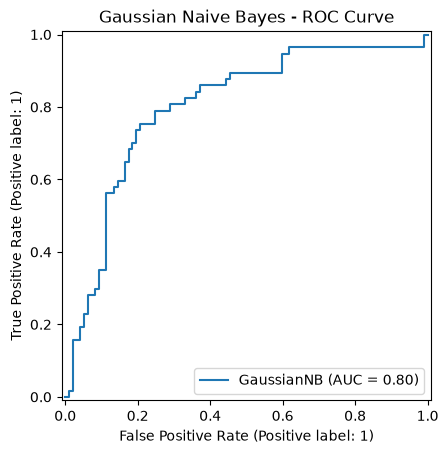

In [59]:
RocCurveDisplay.from_estimator(model, xtest,ytest)
plt.title('Gaussian Naive Bayes - ROC Curve')
plt.show()

Step 11 - Confusion Matrix

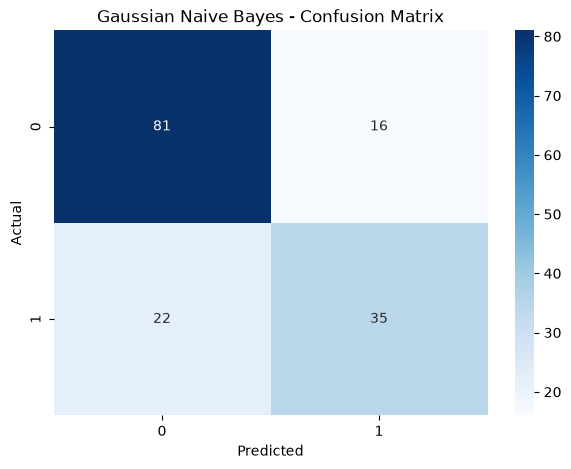

In [60]:
cm = confusion_matrix(ytest, pred)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Gaussian Naive Bayes - Confusion Matrix')
plt.show()